### ROI Extraction

19/10/2026

ORB
[[211 214 222 ... 212 212 221]
 [212 213 218 ... 213 212 212]
 [213 213 217 ... 218 214 208]
 ...
 [ 73  77  77 ...  80  87  84]
 [ 76  74  70 ...  69  76  84]
 [ 63  66  67 ...  61  66  80]]
ORB
[[200 195 191 ... 184 183 183]
 [199 196 193 ... 188 189 191]
 [199 198 196 ... 191 196 201]
 ...
 [155 156 157 ... 180 180 180]
 [155 155 155 ... 179 179 179]
 [155 154 153 ... 179 179 179]]


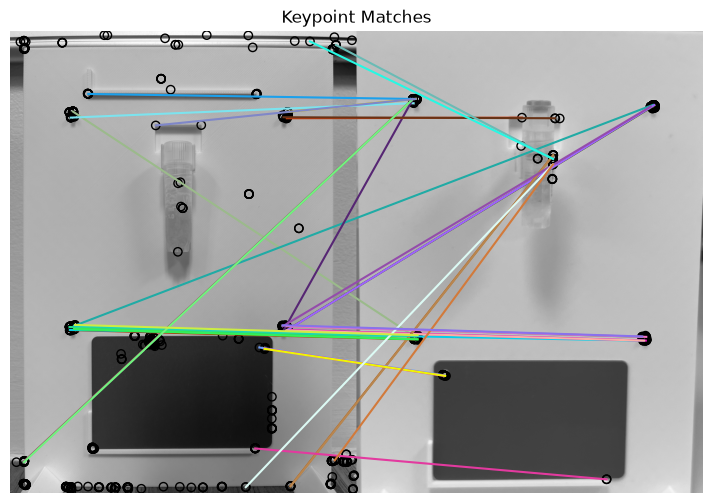

Number of matches: 36


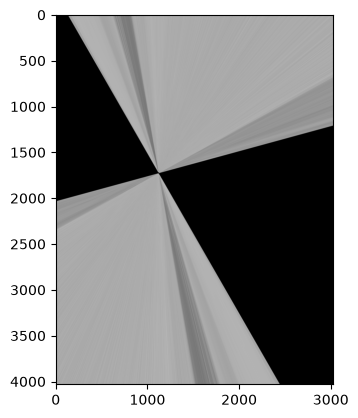

In [1]:
from PIL import Image
import pillow_heif
import os
from sputum_colour import roi_extraction
import cv2
import numpy as np

#dir_path = "/Users/ameliecoy/Library/CloudStorage/OneDrive-SharedLibraries-TheUniversityofManchester/Cheuk ning sharon Chau - Sputum Photos/QUB_06102026"
dir_path = "/Users/ameliecoy/Library/CloudStorage/OneDrive-SharedLibraries-TheUniversityofManchester/Cheuk ning sharon Chau - Sputum Photos/Sputum Photos RG"
file = 'pt62 cf location2.jpeg'

# Get all files in dir_path
files = os.listdir(dir_path)



def imread_compatible(path):
    # TODO - Record original image version before decoding between formats
    # TODO - Update exif metadata extraction to take openCV images instead?
    img = cv2.imread(str(path))
    img_grey = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

    if img is not None:
        return img, img_grey

    # Fall back to HEIC/HEIF decoding
    try:
        heif_file = pillow_heif.read_heif(str(path))
        img_rgb = np.asarray(heif_file)
        return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    except Exception as e:
        print(f"Could not decode {path}: {e}")
        return None, None

dst_image, dst_image_grey = imread_compatible(f"{dir_path}/{file}")
src_image, src_image_grey = imread_compatible(f"{dir_path}/Photo 06-05-2026, 13 30 26.jpg")
roi_extraction.register_target_to_source_image(dst_image_grey, src_image_grey)

# Open the images
#for file in files[120:122]:
 #   src_image, src_image_grey = imread_compatible(f"{dir_path}/{file}")
  #  roi_extraction.register_target_to_source_image(dst_image_grey, src_image_grey)
   # break


